<a href="https://colab.research.google.com/github/mugilansp30/ai-applications-in-digital-design/blob/main/AI_Applications_in_Digital_Design.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>


===== AI-Optimized Logic Mapping Result =====

Best Gate Sequence: ['AND', 'XOR', 'AND', 'OR', 'NOT', 'NOT', 'NOT', 'NOT', 'AND', 'AND']
Total Area Cost: 17




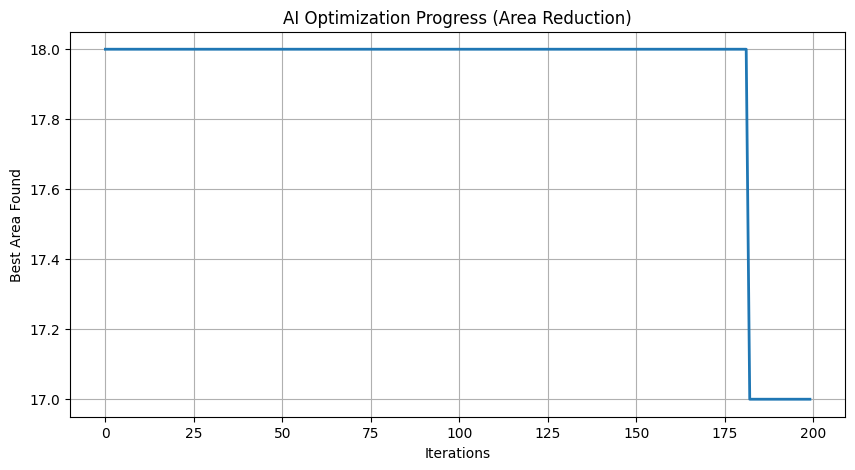

In [ ]:
# Libraries
import random
import numpy as np
import matplotlib.pyplot as plt
# Step 1: Define Logic Gates and Area Cost
logic_gates = {
    "AND": 2,
    "OR": 2,
    "XOR": 3,
    "NAND": 2,
    "NOR": 2,
    "XNOR": 3,
    "NOT": 1
}
# Step 2: Target Circuit Gate Count (Example: 4-bit Logic Block)
target_size = 10   # Approx gate count in design
# Fitness function: Lower area = better
def compute_area(design):
    return sum([logic_gates[g] for g in design])
# Generate andom mapping
def random_design():
    return [random.choice(list(logic_gates.keys())) for _ in range(target_size)]
# AI Optimization
iterations = 200
best_design = random_design()
best_area = compute_area(best_design)
area_progress = []
for i in range(iterations):
    new_design = random_design()
    new_area = compute_area(new_design)
    # If new design is better, select it
    if new_area < best_area:
        best_design = new_design
        best_area = new_area
    area_progress.append(best_area)
# Output Results
print("\n===== AI-Optimized Logic Mapping Result =====\n")
print(f"Best Gate Sequence: {best_design}")
print(f"Total Area Cost: {best_area}")
print("\n=============================================\n")
# Plot performance over iterations
plt.figure(figsize=(10,5))
plt.plot(area_progress, linewidth=2)
plt.title("AI Optimization Progress (Area Reduction)")
plt.xlabel("Iterations")
plt.ylabel("Best Area Found")
plt.grid(True)
plt.show()

✅ AI-Optimized Synthesis Flow Order:
 • Logic Optimization
 • Routing
 • Technology Mapping
 • Placement
 • RTL Mapping

🔥 Minimum Cost (Area + Delay): 12


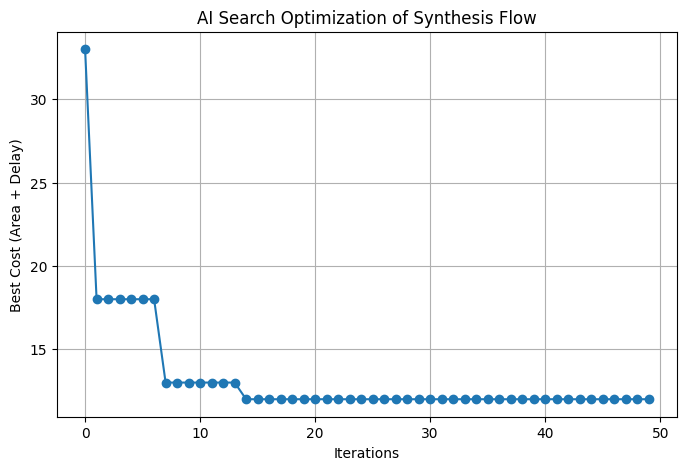

In [ ]:
#EXP 2
import random
import itertools
import matplotlib.pyplot as plt
# Synthesis operations in digital design flow
operations = ["RTL Mapping", "Logic Optimization", "Technology Mapping", "Placement", "Routing"]
# Fitness function = area + delay (lower is better)
def evaluate_flow(flow):
    # Random area and delay scores to simulate EDA tool results
    area = random.randint(5, 20)
    delay = random.randint(5, 20)
    return area + delay
# AI Search to find best sequence
iterations = 50
best_cost_per_iter = []
best_flow = None
best_cost = float("inf")
for i in range(iterations):
    # Generate a random permutation of flow steps
    candidate_flow = random.sample(operations, len(operations))
    # Evaluate cost of this candidate
    cost = evaluate_flow(candidate_flow)
    # Store best result
    if cost < best_cost:
        best_cost = cost
        best_flow = candidate_flow

    best_cost_per_iter.append(best_cost)
# Final Output
print("✅ AI-Optimized Synthesis Flow Order:")
for step in best_flow:
    print(" •", step)
print("\n🔥 Minimum Cost (Area + Delay):", best_cost)
# Plot improvement over time
plt.figure(figsize=(8,5))
plt.plot(best_cost_per_iter, marker="o")
plt.title("AI Search Optimization of Synthesis Flow")
plt.xlabel("Iterations")
plt.ylabel("Best Cost (Area + Delay)")
plt.grid(True)
plt.show()

Simulated path delays (ns): [10.206 19.699 18.324 12.123 11.818 11.834 13.042 15.248 14.319 12.912]

Final optimized constraint: 11 ns
Violations at optimized constraint: 9
Best constraint according to Q-learning: 18 ns


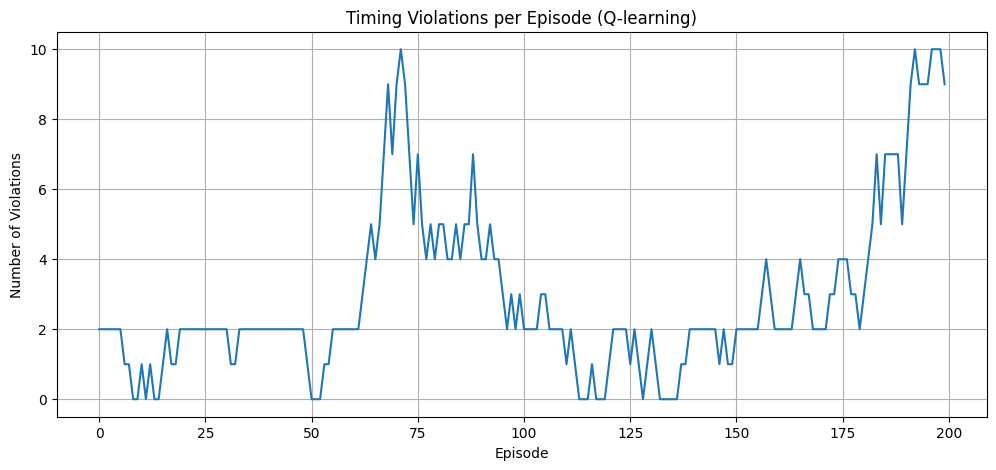

In [ ]:
# EXP 3
# Reinforcement Learning for Timing Constraint Optimization in Digital Design
# Tools: numpy, matplotlib

import numpy as np
import matplotlib.pyplot as plt
# 1) Simulate design timing paths (10 random delay values in ns)
delays = np.round(np.random.uniform(10, 20, 10), 3)
print("Simulated path delays (ns):", delays)
# Initial timing constraint
constraint = 15
# RL Parameters
episodes = 200
alpha = 0.1
gamma = 0.9
actions = [-1, 0, 1]  # decrease, same, increase constraint
Q = {}  # Q-table
# Helper to count timing violations
def violations(constraint, delays):
    return np.sum(delays > constraint)
violations_history = []
# Q-learning training loop
for ep in range(episodes):
    state = constraint
    if state not in Q:
        Q[state] = {a: 0 for a in actions}
    action = np.random.choice(actions)
    new_constraint = state + action
    new_constraint = max(10, min(20, new_constraint))  # safety bounds
    v_old = violations(state, delays)
    v_new = violations(new_constraint, delays)
    reward = (v_old - v_new) * 2
    if v_new == 0 and new_constraint < state:
        reward += 5
    if new_constraint not in Q:
        Q[new_constraint] = {a: 0 for a in actions}
    Q[state][action] += alpha * (reward + gamma * max(Q[new_constraint].values()) - Q[state][action])
    constraint = new_constraint
    violations_history.append(v_new)
final_constraint = constraint
print("\nFinal optimized constraint:", final_constraint, "ns")
print("Violations at optimized constraint:", violations(final_constraint, delays))
# Find best constraint from Q-table
best_constraint = max(Q.keys(), key=lambda s: np.mean(list(Q[s].values())))
print("Best constraint according to Q-learning:", best_constraint, "ns")
# Plot results
plt.figure(figsize=(12,5))
plt.plot(violations_history)
plt.title("Timing Violations per Episode (Q-learning)")
plt.xlabel("Episode")
plt.ylabel("Number of Violations")
plt.grid(True)
plt.show()


Modules (Area, Delay): [(45, 3), (22, 7), (34, 3), (49, 10), (29, 7), (45, 1), (29, 5), (23, 7), (47, 10), (30, 8)]

Best Module Selection: [0, 0, 0, 0, 0, 0, 0, 0, 0, 0]
Total Area: 0
Total Delay: 0
Final Fitness (Area + Delay): 0


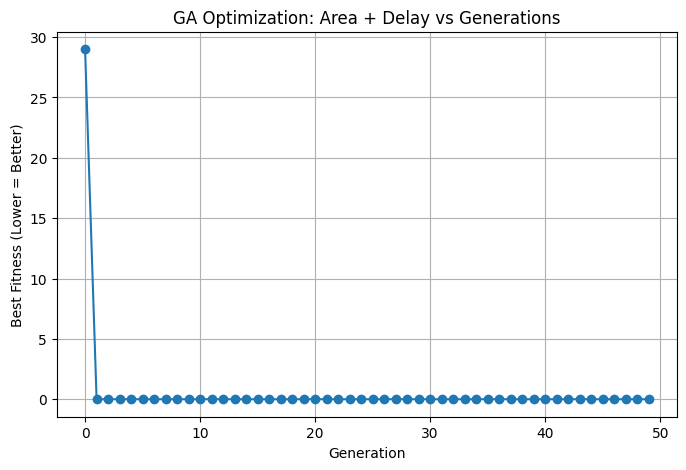

In [ ]:
import random
import numpy as np
import matplotlib.pyplot as plt

# Step 1: Generate random modules (area, delay)
modules = [(random.randint(10, 50), random.randint(1, 10)) for _ in range(10)]
print("Modules (Area, Delay):", modules)

# GA parameters
population_size = 20
generations = 50
mutation_rate = 0.1

# Fitness = total area + total delay (lower is better)
def fitness(individual):
    total_area = sum(modules[i][0] for i in range(len(individual)) if individual[i] == 1)
    total_delay = sum(modules[i][1] for i in range(len(individual)) if individual[i] == 1)
    return total_area + total_delay

def random_individual():
    return [random.randint(0, 1) for _ in range(10)]

def crossover(parent1, parent2):
    point = random.randint(1, len(parent1) - 1)
    return parent1[:point] + parent2[point:]

def mutate(individual):
    for i in range(len(individual)):
        if random.random() < mutation_rate:
            individual[i] = 1 - individual[i]
    return individual

# Initialize population
population = [random_individual() for _ in range(population_size)]
best_fitness_per_gen = []

# Main GA loop
for gen in range(generations):
    scored = [(fitness(ind), ind) for ind in population]
    scored.sort(key=lambda x: x[0])
    best_fitness_per_gen.append(scored[0][0])
    parents = [scored[0][1], scored[1][1]]

    new_population = parents.copy()
    while len(new_population) < population_size:
        child = crossover(parents[0], parents[1])
        child = mutate(child)
        new_population.append(child)
    population = new_population

# Best result
best_individual = min(population, key=fitness)
best_cost = fitness(best_individual)
total_area = sum(modules[i][0] for i in range(len(best_individual)) if best_individual[i] == 1)
total_delay = sum(modules[i][1] for i in range(len(best_individual)) if best_individual[i] == 1)

print("\nBest Module Selection:", best_individual)
print("Total Area:", total_area)
print("Total Delay:", total_delay)
print("Final Fitness (Area + Delay):", best_cost)

# Plot progress
plt.figure(figsize=(8,5))
plt.plot(best_fitness_per_gen, marker='o')
plt.title("GA Optimization: Area + Delay vs Generations")
plt.xlabel("Generation")
plt.ylabel("Best Fitness (Lower = Better)")
plt.grid(True)
plt.show()


Optimized Gate Design: ['NOT', 'NOT', 'NOT', 'NOT', 'NOT', 'NOT', 'NOT', 'NOT', 'NOT', 'NOT']
Minimum Total Gate Cost: 10


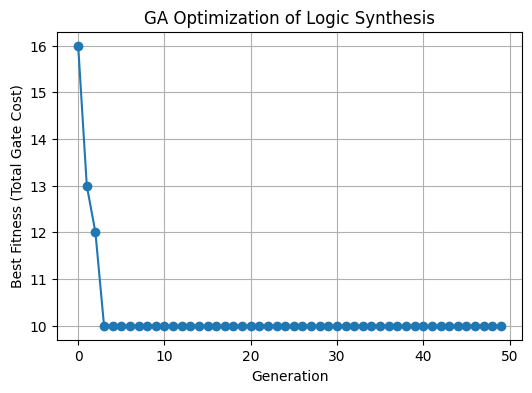

In [ ]:
#EXP 5
import random
import numpy as np
import matplotlib.pyplot as plt

# 1. Available logic gates and their cost (area)
gates = ["AND", "OR", "XOR", "NAND", "NOR", "NOT"]
gate_cost = {"AND":2, "OR":2, "XOR":3, "NAND":2, "NOR":2, "NOT":1}

# Parameters
num_gates = 10
population_size = 20
num_generations = 50
mutation_rate = 0.1

# 2. Fitness function (lower cost = better solution)
def fitness(ind):
    return sum(gate_cost[g] for g in ind)

# 3. Create random design population
def create_population():
    return [[random.choice(gates) for _ in range(num_gates)] for _ in range(population_size)]

# 4. Selection function: choose best 2 designs
def select_parents(population):
    sorted_pop = sorted(population, key=lambda x: fitness(x))
    return sorted_pop[0], sorted_pop[1]

# 5. Crossover function
def crossover(parent1, parent2):
    point = random.randint(1, num_gates - 2)
    child1 = parent1[:point] + parent2[point:]
    child2 = parent2[:point] + parent1[point:]
    return child1, child2

# 6. Mutation function
def mutate(ind):
    for i in range(num_gates):
        if random.random() < mutation_rate:
            ind[i] = random.choice(gates)
    return ind

# GA Execution
population = create_population()
best_fitness_history = []

for gen in range(num_generations):
    parent1, parent2 = select_parents(population)
    new_population = [parent1, parent2]

    while len(new_population) < population_size:
        c1, c2 = crossover(parent1, parent2)
        new_population.append(mutate(c1))
        new_population.append(mutate(c2))

    population = new_population
    best_fitness_history.append(fitness(parent1))

# 7. Final Result
best_design = sorted(population, key=lambda x: fitness(x))[0]
print("Optimized Gate Design:", best_design)
print("Minimum Total Gate Cost:", fitness(best_design))

# 8. Plot optimization path
plt.figure(figsize=(6,4))
plt.plot(best_fitness_history, marker='o')
plt.title("GA Optimization of Logic Synthesis")
plt.xlabel("Generation")
plt.ylabel("Best Fitness (Total Gate Cost)")
plt.grid(True)
plt.show()


Dataset Head:
   Area  Num_Gates  Frequency      Power
0   202        181        824  36.809224
1   448        138        819  55.769765
2   370        109        848  36.137885
3   206         63        437  30.687404
4   171        291        978  52.541186


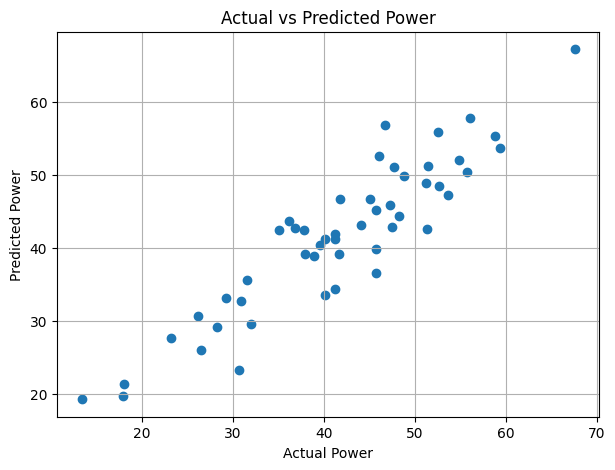


Actual vs Predicted Power Values:
Sample 1: Actual=36.81, Predicted=42.72
Sample 2: Actual=55.77, Predicted=50.37
Sample 3: Actual=36.14, Predicted=43.66
Sample 4: Actual=30.69, Predicted=23.27
Sample 5: Actual=52.54, Predicted=55.98


In [ ]:
#EXP 6
# =============================
# Power Prediction using ML
# =============================

# Step 1: Import Libraries
import numpy as np
import pandas as pd
from sklearn.linear_model import LinearRegression
import matplotlib.pyplot as plt

# Fix random seed for reproducibility
np.random.seed(42)

# Step 2: Data Simulation
samples = 50
area = np.random.randint(100, 500, samples)       # in arbitrary units
num_gates = np.random.randint(50, 300, samples)   # gate count
frequency = np.random.randint(100, 1000, samples) # MHz

# Simulate power: P = α*Area + β*Gates + γ*Freq + noise
noise = np.random.normal(0, 5, samples)
power = 0.05*area + 0.1*num_gates + 0.02*frequency + noise

# Create DataFrame
data = pd.DataFrame({
    'Area': area,
    'Num_Gates': num_gates,
    'Frequency': frequency,
    'Power': power
})

print("Dataset Head:")
print(data.head())

# Step 3: Feature and Label Split
X = data[['Area', 'Num_Gates', 'Frequency']]
y = data['Power']

# Step 4: Train Linear Regression Model
model = LinearRegression()
model.fit(X, y)

# Step 5: Predict Power
y_pred = model.predict(X)

# Step 6: Visualization - Actual vs Predicted Power
plt.figure(figsize=(7,5))
plt.scatter(y, y_pred)
plt.xlabel("Actual Power")
plt.ylabel("Predicted Power")
plt.title("Actual vs Predicted Power")
plt.grid(True)
plt.show()

# Step 7: Print Sample Predictions
print("\nActual vs Predicted Power Values:")
for i in range(5):
    print(f"Sample {i+1}: Actual={y.iloc[i]:.2f}, Predicted={y_pred[i]:.2f}")


Model Accuracy: 0.40

Classification Report:
              precision    recall  f1-score   support

           0       0.58      0.50      0.54        14
           1       0.12      0.17      0.14         6

    accuracy                           0.40        20
   macro avg       0.35      0.33      0.34        20
weighted avg       0.45      0.40      0.42        20


Actual vs Predicted (first 5 samples):
Actual: 0  |  Predicted: 0
Actual: 1  |  Predicted: 0
Actual: 0  |  Predicted: 1
Actual: 0  |  Predicted: 1
Actual: 1  |  Predicted: 1


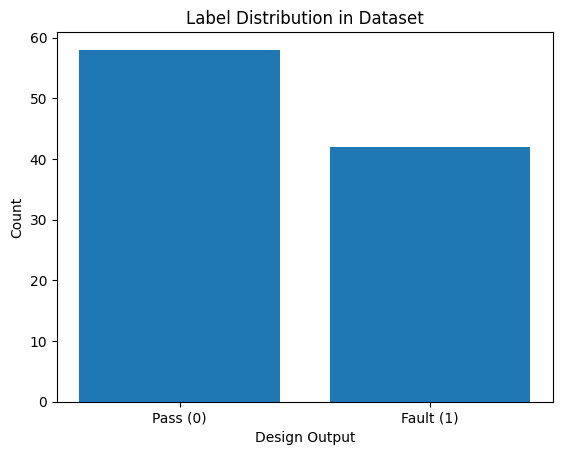

In [ ]:
#EXP 7
# AI-Based Fault Detection in Digital Design using Classification
# Decision Tree Example

import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, classification_report
import matplotlib.pyplot as plt

# 1. Generate Synthetic Dataset
num_samples = 100
X = np.random.randint(0, 2, (num_samples, 5))  # 5 binary input signals
y = np.random.randint(0, 2, num_samples)      # 0 = pass, 1 = fail (fault)

# 2. Split Data into Train/Test
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size = 0.2, random_state = 42
)

# 3. Train Classifier
clf = DecisionTreeClassifier()
clf.fit(X_train, y_train)

# 4. Predict on Test Data
y_pred = clf.predict(X_test)

# 5. Evaluation
accuracy = accuracy_score(y_test, y_pred)
print(f"Model Accuracy: {accuracy:.2f}\n")
print("Classification Report:")
print(classification_report(y_test, y_pred))

# 6. Display first 5 predictions
print("\nActual vs Predicted (first 5 samples):")
for i in range(5):
    print(f"Actual: {y_test[i]}  |  Predicted: {y_pred[i]}")

# Visualize simple bar result
labels = ["Pass (0)", "Fault (1)"]
plt.bar(labels, [sum(y==0), sum(y==1)])
plt.title("Label Distribution in Dataset")
plt.xlabel("Design Output")
plt.ylabel("Count")
plt.show()


=== PROPERTY CHECK REPORT ===
Total Samples: 50
Reset Violations Count: 0
No violations found. Counter obeys reset rule like a good child.


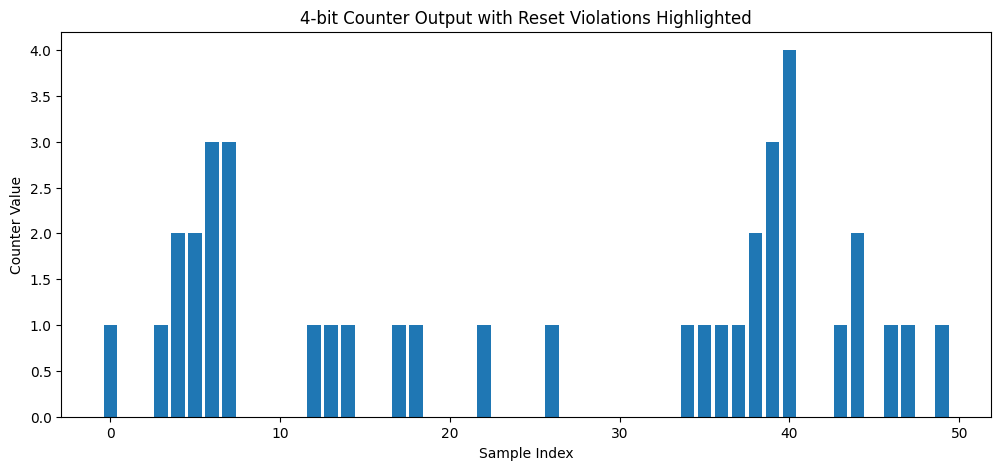

In [ ]:
#EXP 8
import numpy as np
import matplotlib.pyplot as plt
# Number of samples (clock cycles)
num_samples = 50
# Generate random binary inputs for reset and enable
reset = np.random.randint(0, 2, num_samples)
enable = np.random.randint(0, 2, num_samples)
# Counter initialization (4-bit counter: 0 to 15)
counter = np.zeros(num_samples, dtype=int)
# List to store violations
violations = []
# Simulate digital design behavior
for i in range(num_samples):
    if reset[i] == 1:
        counter[i] = 0
    elif enable[i] == 1:
        counter[i] = (counter[i-1] + 1) % 16 if i > 0 else 1
    else:
        counter[i] = counter[i-1] if i > 0 else 0
    # AI-like property check: if reset = 1, output must be 0
    if reset[i] == 1 and counter[i] != 0:
        violations.append(i)
# Output results
print("=== PROPERTY CHECK REPORT ===")
print(f"Total Samples: {num_samples}")
print(f"Reset Violations Count: {len(violations)}")
if violations:
    print("Violation at index positions:", violations)
else:
    print("No violations found. Counter obeys reset rule like a good child.")
# Visualization
plt.figure(figsize=(12,5))
bars = plt.bar(range(num_samples), counter)
# Highlight violations in red
for i in violations:
    bars[i].set_color('red')
plt.title("4-bit Counter Output with Reset Violations Highlighted")
plt.xlabel("Sample Index")
plt.ylabel("Counter Value")
plt.show()


Optimal Parameters: (8, 3)
Minimum Latency: 4.979751363391124


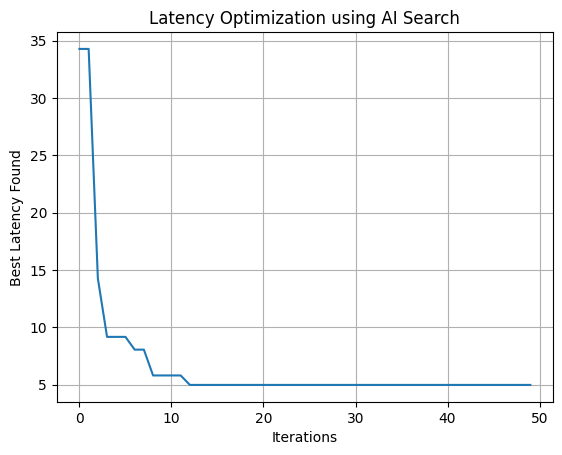

In [ ]:
#EXP 9
import numpy as np
import random
import matplotlib.pyplot as plt

# 1. HLS parameter options
loop_unroll_options = [1, 2, 4, 8]
pipeline_depth_options = [1, 2, 3, 4]

# Base latency (hypothetical)
base_latency = 100

# 2. Latency model (simulated)
def latency(loop_unroll, pipeline_depth):
    # Simulate latency with variation noise
    hardware_effect = base_latency / (loop_unroll * pipeline_depth)
    noise = np.random.rand() * 5  # small randomness like real hardware
    return hardware_effect + noise

best_latency = float('inf')
best_params = None
latency_history = []

# 3. AI-guided random search
for iteration in range(50):
    u = random.choice(loop_unroll_options)
    p = random.choice(pipeline_depth_options)

    current_latency = latency(u, p)

    if current_latency < best_latency:
        best_latency = current_latency
        best_params = (u, p)

    latency_history.append(best_latency)

# 4. Output results
print("Optimal Parameters:", best_params)
print("Minimum Latency:", best_latency)

# 5. Plot performance evolution
plt.plot(latency_history)
plt.title("Latency Optimization using AI Search")
plt.xlabel("Iterations")
plt.ylabel("Best Latency Found")
plt.grid(True)
plt.show()


========= RESULT =========
Best Test Vector Found: [0 1 0 0 0 1 1 1 1 0]
Faults Detected: 10 / 10


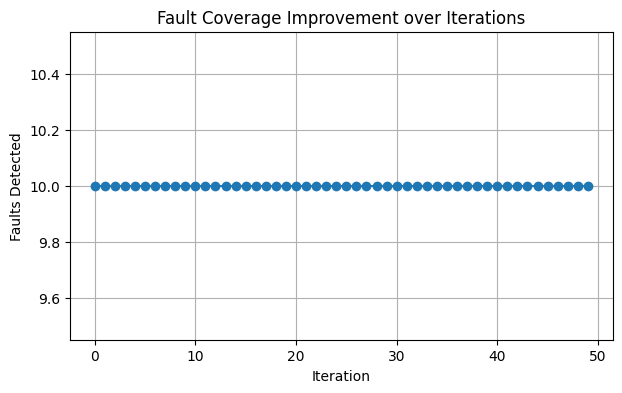

In [ ]:
#EXP 10
import numpy as np
import random
import matplotlib.pyplot as plt

# Parameters
num_gates = 10            # Gates or signals in circuit
num_faults = 10           # Possible fault locations
iterations = 50           # Search iterations
population_size = 5       # Candidate vectors per iteration
mutation_rate = 0.2       # Probability to flip a bit

# Step 1: Simulate faults in circuit (1 = fault at gate)
faults = np.random.randint(0, 2, (num_faults, num_gates))

# Step 2: Generate random test vector
def generate_vector():
    return np.random.randint(0, 2, num_gates)

# Step 3: Evaluate fault coverage for a test vector
def evaluate(vector):
    detected_faults = 0
    for fault in faults:
        if np.any(fault & vector):     # Fault detected if vector activates a faulty gate
            detected_faults += 1
    return detected_faults

# AI search loop
best_vector = None
best_score = -1
coverage_history = []

for it in range(iterations):
    candidates = []

    for _ in range(population_size):
        if best_vector is None:
            vec = generate_vector()
        else:
            # Mutation-based new vector
            vec = best_vector.copy()
            for i in range(num_gates):
                if random.random() < mutation_rate:
                    vec[i] = 1 - vec[i]

        score = evaluate(vec)
        candidates.append((score, vec))

    # Select best vector in this iteration
    round_best_score, round_best_vec = max(candidates, key=lambda x: x[0])

    # Update global best
    if round_best_score > best_score:
        best_score = round_best_score
        best_vector = round_best_vec.copy()

    coverage_history.append(best_score)

# Output results
print("========= RESULT =========")
print("Best Test Vector Found:", best_vector)
print("Faults Detected:", best_score, "/", num_faults)

# Plot coverage progress
plt.figure(figsize=(7,4))
plt.plot(coverage_history, marker='o')
plt.title("Fault Coverage Improvement over Iterations")
plt.xlabel("Iteration")
plt.ylabel("Faults Detected")
plt.grid(True)
plt.show()
